# The Volatility Edge — daily SVXY/VXX backtest

This notebook tests the final **eVRP + term structure + dynamic sizing** strategy
using actual, locally stored SVXY/VXX prices. It runs offline and does not change
the production data store.

**Timing assumption, explicitly requested for this experiment:** treat session
$t$'s EOD SPY/VIX/VIX3M observations as proxies for its 15:45 ET snapshot and
trade at that same session's close. Existing holdings earn the price movement
into the close; new holdings earn returns only after that close. EOD data are
not evidence of historical 15:45 availability, so this is an assumed snapshot
experiment, not a verified intraday replay. Our results are not a reproduction
of the paper's reported Sharpe **1.00** or its 2008–2025 synthetic-proxy backtest.

Sources: [repository paper note](../../docs/research/papers/The_Volatility_Edge.md),
[June 2026 implementation writeup](https://concretumgroup.substack.com/p/automating-a-volatility-strategy),
[SVXY issuer and historical exposure change](https://www.proshares.com/our-etfs/strategic/svxy).
SVXY changed from −1× to −0.5× after February 27, 2018. The experiment starts
after that boundary, using the newer writeup's ×2 dollar-allocation conversion.

In [1]:
import os
import sys
from pathlib import Path

ROOT = next(p.resolve() for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'py' / 'apollo3').is_dir())
OUTPUT = ROOT / 'tmp' / 'volatility_edge_backtest'
OUTPUT.mkdir(parents=True, exist_ok=True)
os.environ.setdefault('MPLCONFIGDIR', str(OUTPUT / 'matplotlib'))
os.environ.setdefault('XDG_CACHE_HOME', str(OUTPUT / 'xdg-cache'))
sys.path.insert(0, str(ROOT / 'py')) if str(ROOT / 'py') not in sys.path else None

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display
from apollo3.calendar import CalendarService
from apollo3.dailypx import read_daily_px
from apollo3.performance import ANNUALIZE, compute_summary_stats
from apollo3.store import FileStore

get_ipython().run_line_magic('matplotlib', 'inline')

DATA_ROOT = Path(os.environ.get('A3_DATA_DIR', ROOT / 'workspace'))
START = pd.Timestamp('2018-02-28')  # issuer's first full session at −0.5x
END = None                       # use the last mutually available daily quote
RV_WINDOW = 10                   # paper
TCOST = 5 / 10_000               # paper: 5 bps per traded dollar, each leg
REBAL_BAND = 2 / 100             # paper: 2 percentage points of fund weight
assert ANNUALIZE == 252          # paper and repository convention agree

print('Python:', sys.executable)
print('Read-only store:', DATA_ROOT)
print('Experiment: EOD proxy for 15:45 signal -> same-session close; initial wealth 1')

Python: /Users/constantinpavlicu/dev/apollo3/venv/bin/python
Read-only store: /Users/constantinpavlicu/dev/apollo3/workspace
Experiment: EOD proxy for 15:45 signal -> same-session close; initial wealth 1


## 1. Available data and the complete session calendar

Signal inputs are SPY, `.VIX` and `.VIX3M`; trading products are SVXY and VXX.
Use adjusted SPY returns for realized volatility and adjusted product prices for
split/distribution-aware fractional research units. Product expenses are already
in prices; no second annual fee is deducted. No integer-share or raw-cash
corporate-action simulation is claimed.

The end date is the latest mutual availability, not today's date. Keep every
US market session, show all missing quotes, and never forward-fill. A missing
quote is allowed only when that product is unheld and untargeted; the ledger
raises if it needs the quote. The original 3:45 snapshots and paper's synthetic
long/inverse index histories are not present in these audited store keys.

In [2]:
st = FileStore(DATA_ROOT)
symbols = ['SPY', '.VIX', '.VIX3M', 'SVXY', 'VXX']
series, coverage = {}, []
for symbol in symbols:
    frame = read_daily_px(st, 'US', symbol, adjusted=True)
    frame.index = pd.DatetimeIndex(frame['date'], name='date')
    if not frame.index.is_unique or not frame.index.is_monotonic_increasing:
        raise ValueError(f'{symbol}: duplicate or unordered dates')
    column = 'close' if symbol.startswith('.') else 'close_adj'
    s = pd.to_numeric(frame[column], errors='raise').rename(symbol)
    if s.notna().any() and not s.dropna().gt(0).all():
        raise ValueError(f'{symbol}: nonpositive prices')
    series[symbol] = s
    coverage.append({'symbol': symbol, 'first': s.first_valid_index(),
                     'last': s.last_valid_index(), 'rows': len(s),
                     'missing_stored': int(s.isna().sum())})

coverage = pd.DataFrame(coverage).set_index('symbol')
display(coverage)
common_end = min(s.last_valid_index() for s in series.values())
end = common_end if END is None else min(pd.Timestamp(END), common_end)
if START < pd.Timestamp('2018-02-28') or START >= end:
    raise ValueError('Choose a supported post-exposure-change interval')
cal = CalendarService().get_calendar('US')
full_calendar = pd.DatetimeIndex(cal.business_days_between(
    max(s.first_valid_index() for s in series.values()).date(), end.date()), name='date')
inputs = pd.concat(series.values(), axis=1).reindex(full_calendar)
test_calendar = full_calendar[full_calendar >= START]
prices = inputs.loc[test_calendar, ['SVXY', 'VXX']]
gaps = inputs.loc[test_calendar].isna()
display(gaps.sum().rename('missing_test_quotes').to_frame())
display(inputs.loc[test_calendar].loc[gaps.any(axis=1)])
if inputs.loc[test_calendar, ['SPY', '.VIX', '.VIX3M']].isna().any().any():
    raise ValueError('Signal inputs are incomplete; no dates may be dropped')
intraday_audit = pd.DataFrame({
    symbol: {'daily': st.has_key(['downloads', 'dailypx', 'US', symbol]),
             'stored_5m': st.has_key(['downloads', 'intradaypx', '5m', 'US', symbol])}
    for symbol in symbols
}).T
display(intraday_audit)
print(f'Test calendar: {test_calendar[0].date()}–{test_calendar[-1].date()}, '
      f'{len(test_calendar):,} sessions. No source data are downloaded or modified.')

,first,last,rows,missing_stored
symbol,,,,
SPY,2008-01-02,2026-07-22,4667,0
.VIX,2008-01-02,2026-06-15,4642,0
.VIX3M,2008-01-02,2026-06-12,4642,1
SVXY,2011-10-04,2026-01-30,3602,0
VXX,2018-01-18,2026-07-22,2134,0


,missing_test_quotes
SPY,0
.VIX,0
.VIX3M,0
SVXY,0
VXX,2


,SPY,.VIX,.VIX3M,SVXY,VXX
date,,,,,
2018-04-30,233.140980,15.93,17.34,24.66,NaN
2018-05-08,235.265193,14.71,16.48,25.16,NaN


,daily,stored_5m
SPY,True,True
.VIX,True,False
.VIX3M,True,False
SVXY,True,False
VXX,True,True


Test calendar: 2018-02-28–2026-01-30, 1,992 sessions. No source data are downloaded or modified.


## 2. Signals and target fund weights

Using the EOD proxy snapshot on session $t$, compute $eRV_t=100\sqrt{252}\,s_{10}(r^{SPY})$ and
$eVRP_t=VIX_t-eRV_t$. We use sample standard deviation (`ddof=1`); the paper
does not specify its variance divisor. Full warm-up uses the preceding stored
history, without discarding in-range market sessions.

| State | SVXY weight | VXX weight |
| --- | --- | --- |
| eVRP > 0; VIX < VIX3M | 2 × VIX / 100 | 0 |
| eVRP ≤ 0; VIX < VIX3M | VIX / 100 | 0 |
| eVRP ≤ 0; VIX > VIX3M | 0 | VIX / 100 |
| Otherwise, including equal VIX/VIX3M | 0 | 0 |

Use the newer writeup's nonpositive-eVRP boundary. Unallocated capital earns
zero. A requested allocation above account equity raises; there is no invented
cap, borrowing policy or clipping. The notebook prints the sample's maximum.

In [3]:
def make_targets(observations):
    '''Map EOD proxy observations to paper-regime fund weights.'''
    returns = observations['SPY'].pct_change(fill_method=None)
    rv = returns.rolling(RV_WINDOW, min_periods=RV_WINDOW).std(ddof=1) * np.sqrt(ANNUALIZE) * 100
    vix, vix3m = observations['.VIX'], observations['.VIX3M']
    evrp = vix - rv
    valid = np.isfinite(rv) & np.isfinite(vix) & np.isfinite(vix3m)
    full_short = valid & (evrp > 0) & (vix < vix3m)
    half_short = valid & (evrp <= 0) & (vix < vix3m)
    long_vol = valid & (evrp <= 0) & (vix > vix3m)
    targets = pd.DataFrame({'SVXY': np.select([full_short, half_short], [2 * vix / 100, vix / 100], 0.0),
                            'VXX': np.where(long_vol, vix / 100, 0.0)}, index=observations.index)
    targets.loc[~valid] = np.nan
    states = np.select([full_short, half_short, long_vol], ['full_short', 'half_short', 'long_vol'], 'cash')
    detail = pd.DataFrame({'eRV': rv, 'eVRP': evrp, 'VIX': vix, 'VIX3M': vix3m,
                           'state': states}, index=observations.index)
    return targets, detail

all_targets, signal_detail = make_targets(inputs)
targets = all_targets.loc[test_calendar]
signal_detail = signal_detail.loc[test_calendar]
if not np.isfinite(targets.to_numpy()).all():
    raise ValueError('Incomplete signal warm-up or observations')
display(signal_detail.join(targets).tail())
display(targets.max().rename('maximum_target_fund_weight').to_frame())

,eRV,eVRP,VIX,VIX3M,state,SVXY,VXX
date,,,,,,,
2026-01-26,13.379026,2.770974,16.150000,19.070000,full_short,0.3230,0.0
2026-01-27,13.520616,2.829384,16.350000,19.219999,full_short,0.3270,0.0
2026-01-28,13.472343,2.877657,16.350000,19.299999,full_short,0.3270,0.0
2026-01-29,13.234732,3.645267,16.879999,19.670000,full_short,0.3376,0.0
2026-01-30,13.283853,4.156148,17.440001,20.070000,full_short,0.3488,0.0


,maximum_target_fund_weight
SVXY,0.7438
VXX,0.8269


## 3. A portfolio ledger with drift and transaction costs

Hold fractional adjusted-price units between rebalances. On each session first
mark existing holdings, then execute **the same session's target**, treating
its EOD inputs as the assumed 15:45 snapshot. Rebalance
only if a fund's current weight differs by more than two percentage points.
That band is applied to actual fund dollar weights; the original −1× proxy band
is not identical in volatility-exposure units after SVXY's ×2 conversion.

At a rebalance, solve costs against post-cost equity:
$E_{after}=E_{before}-c\sum_i|w_iE_{after}-x_i|$,
where $x_i$ are current risky dollar holdings, $w_i$ target weights and
$c=0.0005$. The strategy targets at most one risky product, so the buy/sell
branches have exact closed forms. Sell the previous leg and buy the new one,
charging both. This avoids treating a target-weight return series as if its
holdings rebalanced freely every day. Fees on actual product prices are not
double charged. There is no final artificial liquidation.

In [4]:
def run_backtest(marks, target_weights, fee=TCOST, band=REBAL_BAND):
    '''Replay same-close proxy targets with drifting units and cash.'''
    if not marks.index.equals(target_weights.index) or not marks.columns.equals(target_weights.columns):
        raise ValueError('Marks and targets must have identical session/asset axes')
    if not marks.index.is_unique or not marks.index.is_monotonic_increasing:
        raise ValueError('Session dates must be unique and ordered')
    assets = list(marks.columns)
    units = np.zeros(len(assets))
    cash = previous_nav = 1.0
    records = []
    for i, date in enumerate(marks.index):
        p = marks.iloc[i].to_numpy(dtype=float)
        held = units != 0
        if np.any(held & (~np.isfinite(p) | (p <= 0))):
            raise ValueError(f'{date.date()}: missing mark for held asset')
        old_values = np.zeros(len(assets))
        old_values[held] = units[held] * p[held]
        before = cash + old_values.sum()
        desired = target_weights.iloc[i].to_numpy(dtype=float)
        if not np.isfinite(desired).all() or np.any(desired < 0) or desired.sum() > 1:
            raise ValueError(f'{date.date()}: invalid/unfunded target {desired}; no clipping')
        if np.count_nonzero(desired) > 1:
            raise ValueError('This strategy targets one risk product at a time')
        if np.any((desired > 0) & (~np.isfinite(p) | (p <= 0))):
            raise ValueError(f'{date.date()}: missing execution quote for target asset')
        current_weights = old_values / before
        traded = bool(np.any(np.abs(desired - current_weights) > band))
        cost = turnover_dollars = 0.0
        new_values = old_values.copy()
        if traded:
            active = np.flatnonzero(desired)
            new_values = np.zeros(len(assets))
            units = np.zeros(len(assets))
            if len(active):
                a = active[0]
                w = desired[a]
                other_sales = old_values.sum() - old_values[a]
                buying = w * (before - fee * other_sales) >= old_values[a]
                if buying:
                    cost = fee * (other_sales + w * before - old_values[a]) / (1 + fee * w)
                else:
                    cost = fee * (other_sales + old_values[a] - w * before) / (1 - fee * w)
                after = before - cost
                new_values[a] = w * after
                units[a] = new_values[a] / p[a]
                cash = (1 - w) * after
            else:
                cost = fee * old_values.sum()
                after = before - cost
                cash = after
            turnover_dollars = np.abs(new_values - old_values).sum()
            np.testing.assert_allclose(cost, fee * turnover_dollars)
        else:
            after = before
        np.testing.assert_allclose(cash + new_values.sum(), after)
        record = {'date': date, 'signal_date': date,
                  'nav': after, 'gross_nav': before, 'cash': cash, 'cost': cost,
                  'turnover': turnover_dollars / before, 'traded': traded,
                  'net_return': after / previous_nav - 1}
        for j, asset in enumerate(assets):
            record[f'held_before_{asset}'] = bool(held[j])
            record[f'target_{asset}'] = desired[j]
            record[f'weight_{asset}'] = new_values[j] / after
        records.append(record)
        previous_nav = after
    return pd.DataFrame(records).set_index('date')

## 4. Checks before trusting the real-data result

These small paths check actual economics: same-close trading without credit
for the preceding price move, units drifting
inside the band, costs on both sides of a product switch, liquidation to cash,
and missing-data failure only when a quote is needed. Future observations must
not change past signals or returns. The checks use synthetic prices solely as
fixtures; the reported backtest below uses real stored inputs.

In [5]:
dates = pd.date_range('2024-01-02', periods=4, freq='B')
toy_marks = pd.DataFrame({'SVXY': [100., 100., 102., 102.], 'VXX': [100.] * 4}, index=dates)
toy_targets = pd.DataFrame({'SVXY': [0.4] * 4, 'VXX': [0.] * 4}, index=dates)
toy = run_backtest(toy_marks, toy_targets)
entry_fee = TCOST * 0.4 / (1 + TCOST * 0.4)
assert toy.traded.iloc[0] and not toy.traded.iloc[1]
np.testing.assert_allclose(toy.cost.iloc[0], entry_fee)
np.testing.assert_allclose(toy.net_return.iloc[0], -entry_fee)
np.testing.assert_allclose(toy.net_return.iloc[2], 0.4 * 0.02)
assert not toy.traded.iloc[2]  # drift inside the band is not free daily rebalancing
outside_marks = toy_marks.copy()
outside_marks.iloc[2:, 0] = 130.
outside = run_backtest(outside_marks, toy_targets)
assert outside.traded.iloc[2] and outside.cost.iloc[2] > 0
np.testing.assert_allclose(outside.weight_SVXY.iloc[2], 0.4)
switch_targets = toy_targets.copy()
switch_targets.iloc[1] = [0., 0.2]
switch_targets.iloc[2:] = [0., 0.]
switched = run_backtest(toy_marks, switch_targets)
assert switched.weight_SVXY.iloc[1] == 0 and switched.weight_VXX.iloc[1] > 0
np.testing.assert_allclose(switched.cost, switched.turnover * switched.gross_nav * TCOST)
assert switched.traded.iloc[2] and switched.cash.iloc[2] == switched.nav.iloc[2]
missing_idle = toy_marks.copy()
missing_idle['VXX'] = np.nan
pd.testing.assert_frame_equal(run_backtest(missing_idle, toy_targets), toy)
missing_held = toy_marks.copy()
missing_held.iloc[2, 0] = np.nan
try:
    run_backtest(missing_held, toy_targets)
except ValueError as exc:
    assert 'missing mark' in str(exc)
else:
    raise AssertionError('Missing held quotes must fail')
unfunded = toy_targets.copy()
unfunded.iloc[0] = [1.01, 0]
try:
    run_backtest(toy_marks, unfunded)
except ValueError as exc:
    assert 'unfunded' in str(exc)
else:
    raise AssertionError('Unfunded weights must not be clipped or borrowed')

# Source boundary cases: positive / zero / negative eVRP and equal term levels.
boundary_input = pd.DataFrame({'SPY': [100.] * (RV_WINDOW + 1),
                              '.VIX': [20.] * (RV_WINDOW + 1),
                              '.VIX3M': [25.] * (RV_WINDOW + 1)})
bweights, _ = make_targets(boundary_input)
np.testing.assert_allclose(bweights.iloc[-1], [0.4, 0])
boundary_input['SPY'] = 100 * np.cumprod([1.] + [1.01, 0.99] * (RV_WINDOW // 2))
last_rv = (boundary_input.SPY.pct_change(fill_method=None).rolling(RV_WINDOW)
           .std(ddof=1).iloc[-1] * np.sqrt(ANNUALIZE) * 100)
boundary_input['.VIX'] = last_rv
boundary_input['.VIX3M'] = last_rv + 1
zero_short, _ = make_targets(boundary_input)
np.testing.assert_allclose(zero_short.iloc[-1], [last_rv / 100, 0])
boundary_input['.VIX3M'] = last_rv - 1
zero_long, _ = make_targets(boundary_input)
np.testing.assert_allclose(zero_long.iloc[-1], [0, last_rv / 100])
boundary_input['.VIX3M'] = boundary_input['.VIX']
equal_term, _ = make_targets(boundary_input)
np.testing.assert_allclose(equal_term.iloc[-1], [0, 0])
assert all_targets.loc[test_calendar].sum(axis=1).le(1).all()
assert len(prices) == len(test_calendar)
# A position first opened after the 100 -> 200 move receives none of it.
late_entry_marks = toy_marks.copy()
late_entry_marks['SVXY'] = [100., 200., 200., 200.]
late_entry_targets = toy_targets.copy()
late_entry_targets.iloc[0] = [0., 0.]
late_entry = run_backtest(late_entry_marks, late_entry_targets)
assert not late_entry.traded.iloc[0] and late_entry.traded.iloc[1]
np.testing.assert_allclose(late_entry.net_return.iloc[1], -entry_fee)
np.testing.assert_allclose(late_entry.nav.iloc[1:], 1 - entry_fee)
assert not late_entry.traded.iloc[2:].any()
print('PASS: same-close entry, no preceding-move P&L, drift, costs, gaps and no borrowing')

PASS: same-close entry, no preceding-move P&L, drift, costs, gaps and no borrowing


## 5. Actual-price result and matched SPY comparison

Normalized wealth starts at 1 immediately before the first execution close.
Evaluation includes the first session's entry cost; both portfolios can enter
at that close and earn market returns afterward. Both portfolios pay the same
5 bps on traded dollars. SPY buys once and holds, on matching dates. Cash earns
zero. Returns below include entry costs and retain all flat/cash sessions.
Annualized Sharpe is daily mean divided by sample standard deviation, times
$\sqrt{252}$, with zero risk-free return. Drawdown uses ordinary wealth peaks,
including initial wealth, rather than the paper's median-adjusted alternative.

In [6]:
ledger = run_backtest(prices, targets)
spy_marks = inputs.loc[test_calendar, ['SPY']]
spy_targets = pd.DataFrame(1.0, index=test_calendar, columns=['SPY'])
spy_ledger = run_backtest(spy_marks, spy_targets)
evaluation_dates = test_calendar
returns = pd.DataFrame({'Strategy': ledger.loc[evaluation_dates, 'net_return'],
                        'SPY buy & hold': spy_ledger.loc[evaluation_dates, 'net_return']})
stats = pd.DataFrame({name: compute_summary_stats(returns[name]) for name in returns}).T
stats = stats[['cagr', 'volatility', 'sharpe', 'max_drawdown']]
stats['correlation_to_SPY'] = [returns[name].corr(returns['SPY buy & hold']) for name in returns]
display(stats.style.format({'cagr': '{:.2%}', 'volatility': '{:.2%}',
                            'sharpe': '{:.3f}', 'max_drawdown': '{:.2%}',
                            'correlation_to_SPY': '{:.3f}'}))
print('Evaluation:', evaluation_dates[0].date(), 'through', evaluation_dates[-1].date(),
      '| observations:', len(evaluation_dates))
print('Rebalance days:', int(ledger.traded.sum()),
      '| average annual turnover:', ledger.loc[evaluation_dates, 'turnover'].mean() * ANNUALIZE)
display(signal_detail.state.loc[evaluation_dates].value_counts(normalize=True).rename('decision_share').to_frame())
yearly = returns.groupby(returns.index.year).agg(lambda r: (1 + r).prod() - 1)
display(yearly.style.format('{:.2%}'))

,cagr,volatility,sharpe,max_drawdown,correlation_to_SPY
Strategy,12.51%,18.72%,0.721,-30.11%,0.063
SPY buy & hold,14.34%,19.37%,0.789,-33.72%,1.000


Evaluation: 2018-02-28 through 2026-01-30 | observations: 1992
Rebalance days: 910 | average annual turnover: 12.599837371283733


,decision_share
state,
full_short,0.780120
half_short,0.138052
cash,0.045181
long_vol,0.036647


,Strategy,SPY buy & hold
date,,
2018,-2.13%,-6.30%
2019,1.45%,31.22%
2020,44.43%,18.33%
2021,22.50%,28.73%
2022,4.29%,-18.18%
2023,23.53%,26.18%
2024,3.61%,24.89%
2025,8.51%,17.72%
2026,-0.22%,1.47%


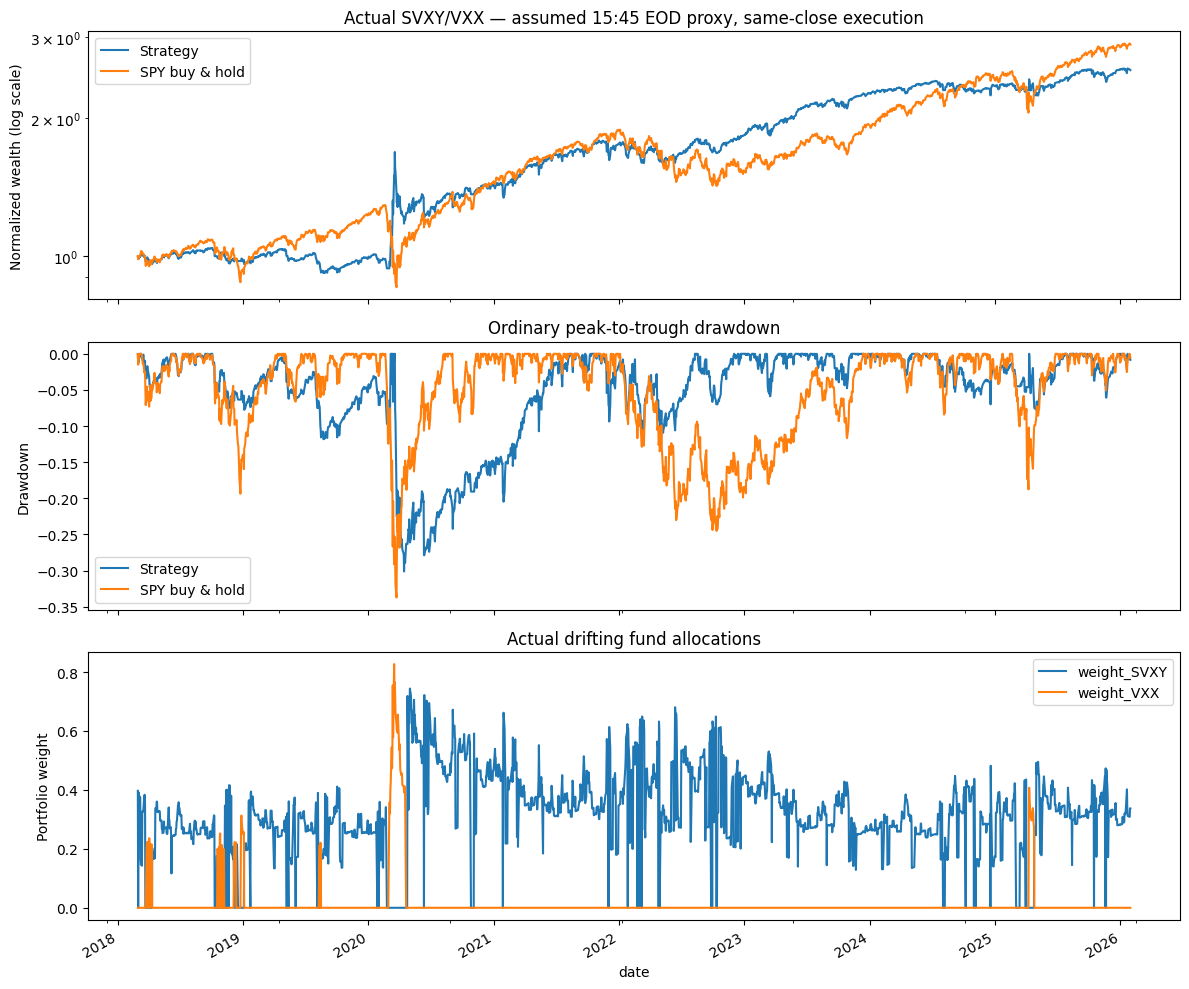

In [7]:
wealth = pd.DataFrame({'Strategy': ledger.nav, 'SPY buy & hold': spy_ledger.nav})
drawdown = wealth.div(wealth.cummax().clip(lower=1.0)) - 1
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
wealth.plot(ax=axes[0], logy=True, title='Actual SVXY/VXX — assumed 15:45 EOD proxy, same-close execution')
axes[0].set_ylabel('Normalized wealth (log scale)')
drawdown.plot(ax=axes[1], title='Ordinary peak-to-trough drawdown')
axes[1].set_ylabel('Drawdown')
ledger[['weight_SVXY', 'weight_VXX']].plot(ax=axes[2], title='Actual drifting fund allocations')
axes[2].set_ylabel('Portfolio weight')
plt.tight_layout()
plt.show()

## 6. Final causality, data-gap and reconciliation audit

Changing session $t$'s assumed signal can change its order and transaction cost
at that same close, but cannot change the gross P&L already earned by existing
holdings into that close. Changes after $t$ must leave the ledger through $t$
unchanged. This checks the stipulated proxy clock; it does not prove that EOD
observations were actually available at 15:45. Gaps are retained and
are printed with the actual held/target flags. Exports go only to ignored
`tmp/volatility_edge_backtest/`.

In [8]:
active_dates = targets.index[targets.sum(axis=1) > 0]
cut = active_dates[len(active_dates) // 2]
changed_inputs = inputs.copy()
changed_inputs.loc[changed_inputs.index > cut, 'SPY'] *= 1.25
changed_targets, _ = make_targets(changed_inputs)
pd.testing.assert_frame_equal(all_targets.loc[:cut], changed_targets.loc[:cut])
changed_prices = prices.copy()
changed_prices.loc[changed_prices.index > cut] *= 1.25
future_ledger = run_backtest(changed_prices, targets)
pd.testing.assert_frame_equal(ledger.loc[:cut], future_ledger.loc[:cut])
changed_intent = targets.copy()
changed_intent.loc[cut] = [0., 0.]
intent_ledger = run_backtest(prices, changed_intent)
pd.testing.assert_frame_equal(ledger.loc[ledger.index < cut],
                              intent_ledger.loc[intent_ledger.index < cut])
np.testing.assert_allclose(ledger.at[cut, 'gross_nav'], intent_ledger.at[cut, 'gross_nav'])
assert intent_ledger.loc[cut, ['target_SVXY', 'target_VXX']].eq(0).all()
assert ledger.loc[cut, ['target_SVXY', 'target_VXX']].sum() > 0
assert ledger.index.equals(test_calendar)
assert ledger.cash.ge(0).all()
np.testing.assert_allclose((1 + ledger.net_return).cumprod(), ledger.nav)
assert ledger.signal_date.eq(ledger.index).all()
for symbol in ['SVXY', 'VXX']:
    missing = prices[symbol].isna()
    assert not ledger.loc[missing, f'held_before_{symbol}'].any()
    assert ledger.loc[missing, f'target_{symbol}'].eq(0).all()
display(ledger.loc[gaps[['SVXY', 'VXX']].any(axis=1),
                   ['held_before_VXX', 'target_VXX', 'weight_VXX', 'nav']])
returns.to_csv(OUTPUT / 'daily_returns.csv')
ledger.to_csv(OUTPUT / 'ledger.csv')
stats.to_csv(OUTPUT / 'summary.csv')
coverage.to_csv(OUTPUT / 'data_coverage.csv')
signal_detail.join(targets).to_csv(OUTPUT / 'signals.csv')
print('PASS: full calendar, future-data invariance, same-session intent, no retroactive gross P&L, gap handling, NAV reconciliation')
print('Saved research outputs to', OUTPUT)

,held_before_VXX,target_VXX,weight_VXX,nav
date,,,,
2018-04-30,False,0.0,0.0,0.978548
2018-05-08,False,0.0,0.0,0.984868


PASS: full calendar, future-data invariance, same-session intent, no retroactive gross P&L, gap handling, NAV reconciliation
Saved research outputs to /Users/constantinpavlicu/dev/apollo3/tmp/volatility_edge_backtest


## What this result proves

This is an actual-product, daily-data experiment with the newer writeup's
SVXY conversion and same-close execution under an assumed 15:45 snapshot
represented by EOD inputs. It is not the published 2008–2025 proxy result:
the instruments/sample differ and actual intraday snapshot values are absent. The later writeup does not provide a fresh actual-SVXY backtest target.
Signal formation here uses adjusted daily SPY returns and sample standard
deviation; these are explicit research conventions. Actual VXX prices include
market/NAV dislocations such as 2022, which the paper's proxies avoid.

To reproduce the original timing, obtain aligned historical SPY/VIX/VIX3M
snapshots at the completed 15:45 (12:45 early-close) signal time and matching
trading-product closes, with a documented session calendar. To reproduce its
full period, obtain the paper's long/inverse benchmark-index histories and
fee/cash conventions. The EOD-for-15:45 substitution here is a user-requested
assumption and may differ from a historically executable intraday signal.
There is no fitted model, parameter search, interest income, margin borrowing,
production deployment or broker connectivity in this notebook.

## Addendum — remaining implementation gaps

Same-day close execution is now implemented, together with the dual signals,
SVXY ×2 sizing, holding drift, transaction costs and the rebalance band.
The remaining differences from the published experiment are:

| Area | Current notebook | Remaining gap |
| --- | --- | --- |
| Signal snapshot | Uses EOD SPY, VIX and VIX3M observations as the assumed 15:45 ET snapshot; executes at the same close. | Actual 15:45 observations can differ from EOD values. The final 15 minutes are therefore included in the proxy information set. This assumption can introduce lookahead relative to the real signal cutoff; the timing checks cannot verify historical 15:45 availability. |
| Instruments and fees | Uses actual SVXY/VXX adjusted prices. SVXY's −0.5× daily exposure is converted with twice the dollar allocation. Product expenses are already reflected in prices. | The paper uses synthetic −1× inverse/+1× benchmark histories with assumed annual fees. Matching daily exposure does not match compounded performance, expenses, tracking or VXX market/NAV dislocations. The newer writeup provides the tradable mapping, but no independently verified actual-SVXY backtest target. |
| Evaluation period | February 28, 2018–January 30, 2026, including the first close's entry cost. | The published headline result covers January 2008–May 2025. Its earlier regimes and longer history are absent, and our sample includes later observations. SVXY's exposure change determines our starting boundary; its stored coverage determines the endpoint. |
| Rebalance-band units | Two percentage points of actual fund weight. | Two points in a −1× proxy allocation are not equivalent to two points in SVXY allocation: the latter represents approximately one point of −1× daily exposure. The source does not fully resolve how to translate the band when doubling SVXY dollars, so turnover can differ. |
| Signal conventions | Adjusted daily SPY returns; 10-return sample standard deviation with `ddof=1`. | The paper uses a partial current-day SPY return at signal time and does not fully specify the variance divisor or price-adjustment convention. Exact numerical signal parity is unverified. |
| Fill and portfolio accounting | Fractional adjusted-price units, close-price fills and a flat 5 bps charge on each traded dollar. Cash earns zero; new holdings earn price returns only after entry. | This research ledger does not replay whole-share rounding, actual auction fills, bid/ask quotes, rejected orders or realized execution slippage. It is not a broker-execution audit. |
| Funding outside the observed sample | Unfunded targets raise instead of borrowing or being clipped. | The source supplies no complete funding/capping rule when the full-short SVXY weight $2\,VIX/100$ exceeds account equity. That boundary is VIX above 50, derived from the sizing formula; it is not an added trading threshold. It was not triggered in this run. |

To establish a closer replication, first match the sample and instruments, then
replace the EOD signal proxies with aligned historical 15:45 snapshots (12:45
on early-close sessions) and resolve the band/estimator conventions. Those
comparisons have not been run, so the Sharpe difference cannot be attributed
to any one gap. The published Sharpe **1.00** remains a source result, not a
validation target for an otherwise different actual-product experiment.
